# Monte-Carlo pour le call européen
**Projet Math et Assurance · ESPRIT · 2026–2027 · Encadrant : M. Chebbi**

**But :** calculer le prix d'un call européen par simulation de Monte-Carlo, vérifier qu'on retrouve le prix exact de Black-Scholes, puis réduire l'erreur avec deux méthodes : variables antithétiques et variable de contrôle. Tous les tirages aléatoires sont fabriqués par la **méthode de Box-Muller**.

## 1. Imports et paramètres

In [1]:
# ============ Imports ============
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# ============ Paramètres ============
S0    = 100.0      # prix de l'action aujourd'hui
K     = 100.0      # prix d'exercice (strike)
T     = 1.0        # maturité : 1 an
r     = 0.05       # taux sans risque
sigma = 0.20       # volatilité
N     = 1_000_000  # nombre de simulations

rng = np.random.default_rng(2026)   # générateur fixé par une graine : mêmes résultats à chaque exécution
z95 = 1.96                          # quantile de N(0,1) : P(|Z| <= 1.96) = 95 %

## 2. Méthode de Box-Muller

Le générateur ne donne que des nombres **uniformes** sur $[0,1[$. Pour simuler le prix de l'action, il faut des tirages $Z \sim \mathcal N(0,1)$. La méthode de Box-Muller les fabrique à partir de deux uniformes $U_1, U_2$ :
$$Z = \sqrt{-2\ln U_1}\;\cos(2\pi U_2) \ \sim\ \mathcal N(0,1).$$
On prend $U_1 = 1 - U$ (qui est dans $]0,1]$) pour ne jamais calculer $\ln 0$.

Moyenne        = -0.0010   (théorie 0)
Variance       = 0.9987   (théorie 1)
P(|Z| <= 1.96) = 0.9503   (théorie 0.95)


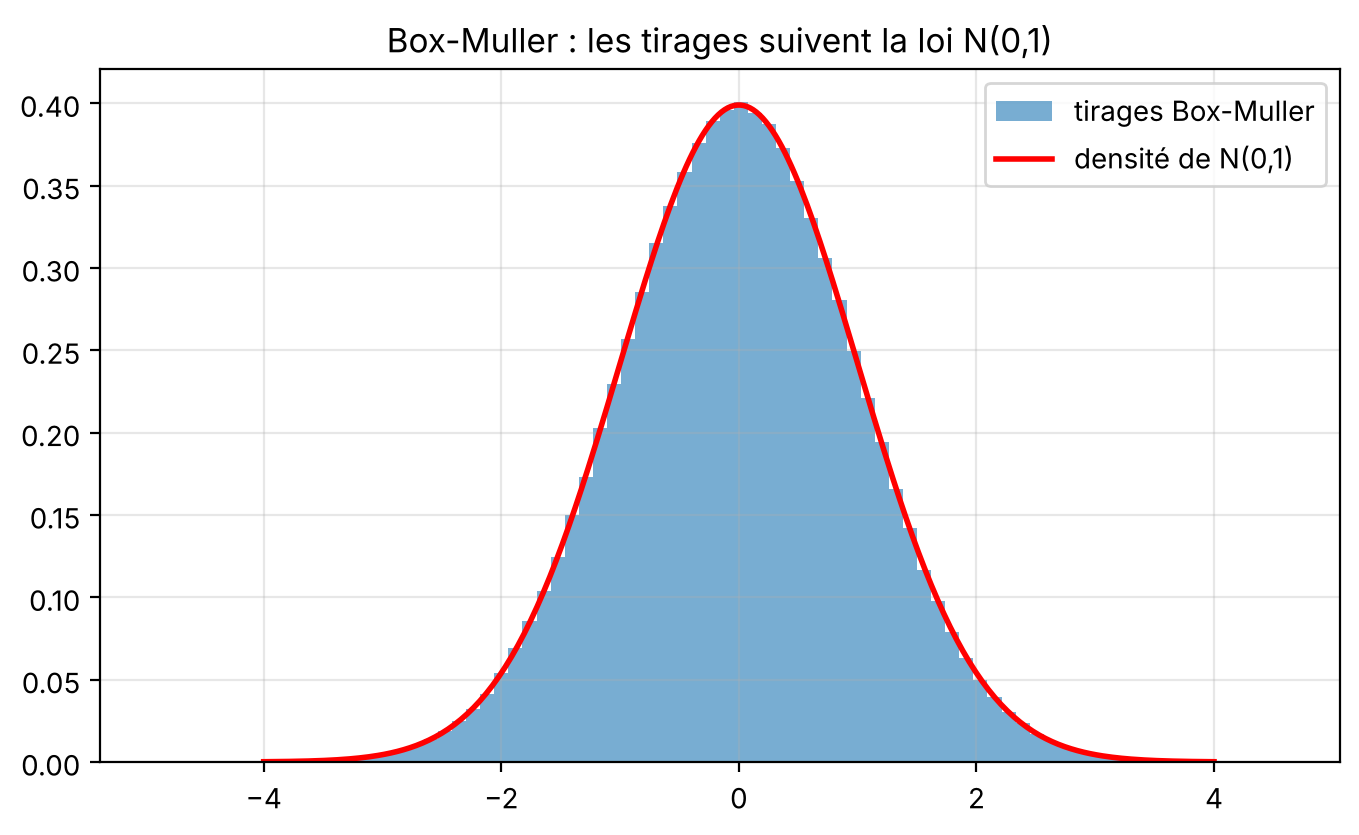

In [2]:
# ============ Box-Muller : uniformes -> N(0,1) ============
def box_muller(n, rng):
    U1 = 1.0 - rng.random(n)                              # uniforme sur ]0,1]
    U2 = rng.random(n)                                    # uniforme sur [0,1[
    return np.sqrt(-2.0 * np.log(U1)) * np.cos(2.0 * np.pi * U2)

# Vérification : les tirages doivent avoir moyenne 0 et variance 1
Z = box_muller(N, rng)
print(f"Moyenne        = {Z.mean():.4f}   (théorie 0)")
print(f"Variance       = {Z.var(ddof=1):.4f}   (théorie 1)")
print(f"P(|Z| <= 1.96) = {np.mean(np.abs(Z) <= 1.96):.4f}   (théorie 0.95)")

x = np.linspace(-4, 4, 300)
plt.figure(figsize=(8, 4.5))
plt.hist(Z, bins=80, density=True, alpha=0.6, label="tirages Box-Muller")
plt.plot(x, norm.pdf(x), "r", lw=2, label="densité de N(0,1)")
plt.title("Box-Muller : les tirages suivent la loi N(0,1)")
plt.legend(); plt.grid(alpha=0.3)
plt.savefig("figures/fig_box_muller.png", dpi=160, bbox_inches="tight")
plt.show()

## 3. Formule analytique de Black-Scholes (référence)

$$C_{BS} = S_0\,N(d_1) - K e^{-rT} N(d_2),\qquad d_1 = \frac{\ln(S_0/K) + (r + \sigma^2/2)T}{\sigma\sqrt T},\qquad d_2 = d_1 - \sigma\sqrt T.$$
C'est le **prix exact** du call : il sert à mesurer l'erreur de Monte-Carlo.

In [3]:
# ============ Formule exacte de Black-Scholes ============
def bs_call():
    d1 = (np.log(S0 / K) + (r + sigma**2 / 2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    return S0 * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)

C_exact = bs_call()
print(f"Prix exact du call : C = {C_exact:.4f}")

Prix exact du call : C = 10.4506


## 4. Estimateur Monte-Carlo standard

La solution exacte de l'EDS $dS_t = rS_t\,dt + \sigma S_t\,dW_t$ donne le prix final à partir d'un tirage $Z$ :
$$S_T = S_0 \exp\!\Big[\Big(r - \frac{\sigma^2}{2}\Big)T + \sigma\sqrt T\,Z\Big],\qquad \text{payoff du call} = \max(S_T - K, 0).$$

Le prix est une espérance : $C = \mathbb E[Y]$ avec $Y = e^{-rT}\max(S_T - K, 0)$. On la remplace par une moyenne de $N$ simulations :
$$\hat C = \frac1N\sum_{i=1}^N Y_i,\qquad SE = \frac{s}{\sqrt N},\qquad IC_{95\%} = \hat C \pm 1{,}96\,SE,$$
où $s$ est l'écart-type des $Y_i$. On compare le résultat au prix analytique (Black-Scholes) : erreur $= |C_{\text{analytique}} - \hat C|$.

In [4]:
# ============ Estimateur Monte-Carlo standard ============
def mc_call_standard(N, rng):
    Z  = box_muller(N, rng)                  # 1) tirages N(0,1)
    ST = S0 * np.exp((r - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * Z)   # 2) prix finaux
    Y  = np.exp(-r * T) * np.maximum(ST - K, 0.0)                        # 3) payoffs actualisés
    prix = Y.mean()                          # 4) moyenne = prix estimé
    se   = Y.std(ddof=1) / np.sqrt(N)        #    erreur standard
    return prix, se

C_mc, se_mc = mc_call_standard(N, rng)
print(f"C_MC = {C_mc:.4f}   IC 95 % = [{C_mc - z95*se_mc:.4f} ; {C_mc + z95*se_mc:.4f}]   C exact = {C_exact:.4f}")
print(f"Erreur |C_analytique - C_MC| = {abs(C_exact - C_mc):.6f}")

C_MC = 10.4370   IC 95 % = [10.4081 ; 10.4658]   C exact = 10.4506
Erreur |C_analytique - C_MC| = 0.013624


### Intervalle de confiance à 95 % en fonction de $N$ ($10^3 \le N \le 10^6$)

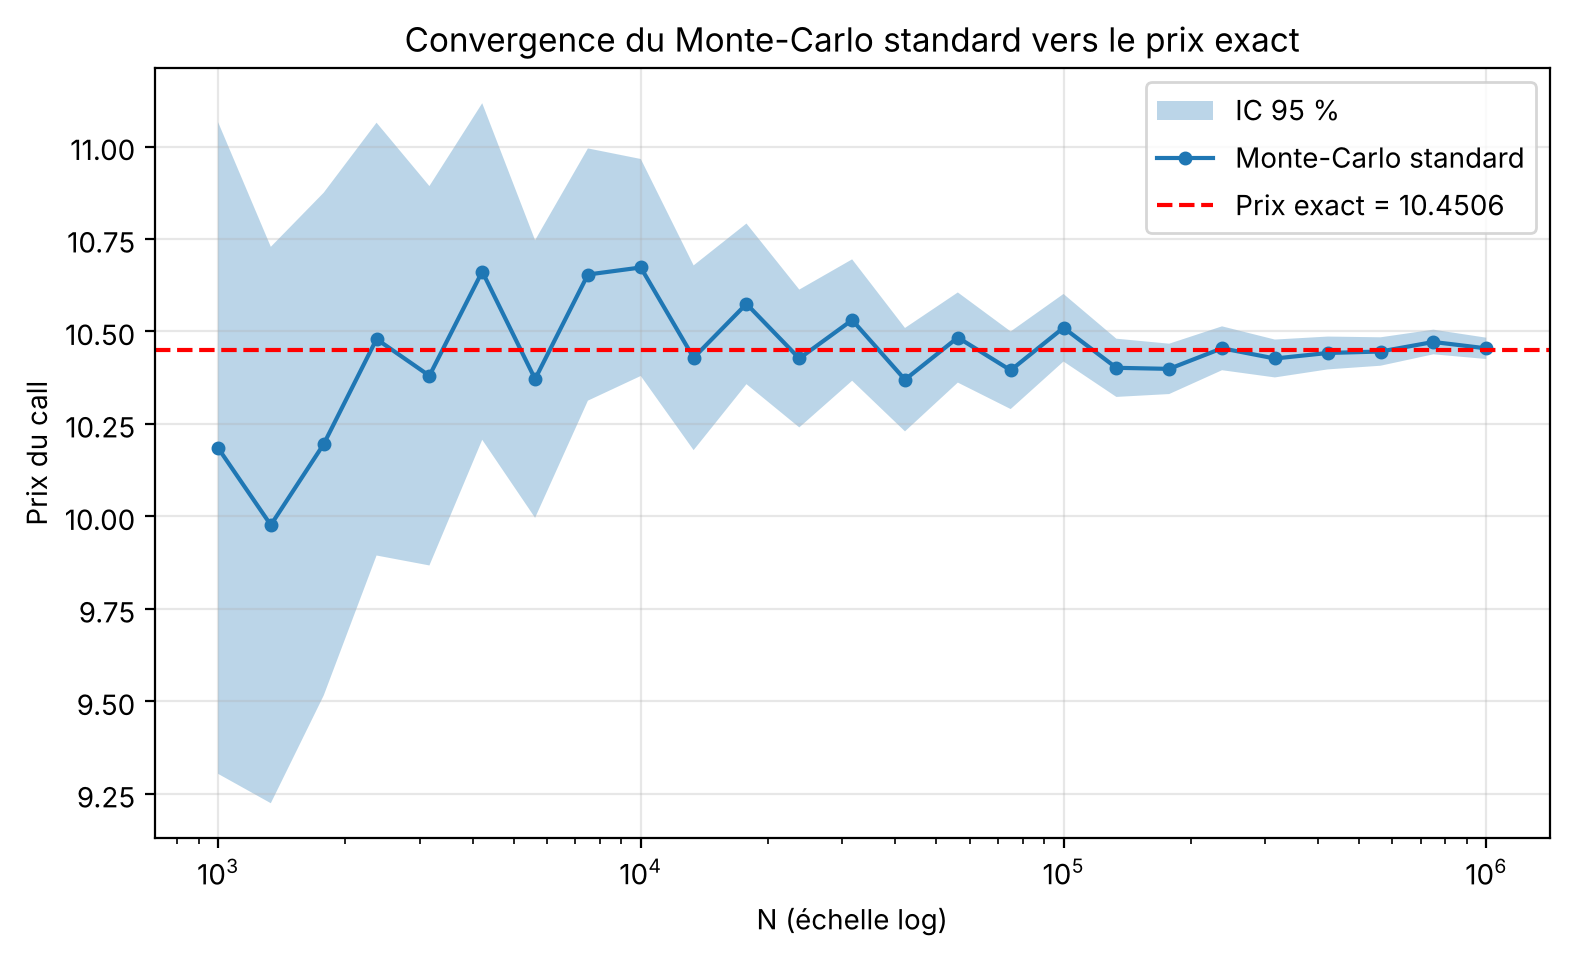

Le prix exact est dans l'IC pour 100% des 25 valeurs de N


In [5]:
# ============ Convergence vers le prix exact ============
liste_N = np.unique(np.logspace(3, 6, 25).astype(int))
prix, demi_ic = [], []
for n in liste_N:
    p, se = mc_call_standard(n, rng)
    prix.append(p)
    demi_ic.append(z95 * se)
prix, demi_ic = np.array(prix), np.array(demi_ic)

plt.figure(figsize=(9, 5))
plt.fill_between(liste_N, prix - demi_ic, prix + demi_ic, alpha=0.3, label="IC 95 %")
plt.plot(liste_N, prix, "o-", ms=4, label="Monte-Carlo standard")
plt.axhline(C_exact, color="red", ls="--", label=f"Prix exact = {C_exact:.4f}")
plt.xscale("log"); plt.xlabel("N (échelle log)"); plt.ylabel("Prix du call")
plt.title("Convergence du Monte-Carlo standard vers le prix exact")
plt.legend(); plt.grid(alpha=0.3)
plt.savefig("figures/fig_ic_vs_N.png", dpi=160, bbox_inches="tight")
plt.show()

dans_ic = np.mean(np.abs(prix - C_exact) <= demi_ic)
print(f"Le prix exact est dans l'IC pour {dans_ic:.0%} des {len(liste_N)} valeurs de N")

### Prix pour les puissances de 10 : $N = 10^1, 10^2, \dots, 10^6$

In [6]:
# ============ Prix et IC pour N = 10, 100, ..., 10^6 ============
puissances = [10**k for k in range(1, 7)]
print(f"{'N':>9} | {'Prix MC':>8} | {'IC 95 %':^19} | {'|C_MC - C|':>10}")
print("-" * 58)
for n in puissances:
    p, se = mc_call_standard(n, rng)
    print(f"{n:>9} | {p:8.4f} | [{p - z95*se:7.4f} ; {p + z95*se:7.4f}] | {abs(p - C_exact):10.4f}")

        N |  Prix MC |       IC 95 %       | |C_MC - C|
----------------------------------------------------------
       10 |  11.9906 | [ 3.8810 ; 20.1002] |     1.5400
      100 |  10.1197 | [ 7.1120 ; 13.1275] |     0.3309
     1000 |  10.4897 | [ 9.5733 ; 11.4061] |     0.0391
    10000 |  10.5740 | [10.2834 ; 10.8645] |     0.1234
   100000 |  10.4234 | [10.3326 ; 10.5141] |     0.0272
  1000000 |  10.4371 | [10.4083 ; 10.4660] |     0.0134


### Trajectoire de l'estimateur : stabilité

On suit la moyenne $\hat C_n = \frac1n\sum_{i=1}^n Y_i$ au fur et à mesure que $n$ augmente, sur une seule simulation de $N$ payoffs. Elle doit se stabiliser autour du prix exact, dans l'enveloppe $C \pm 1{,}96\,s/\sqrt n$.

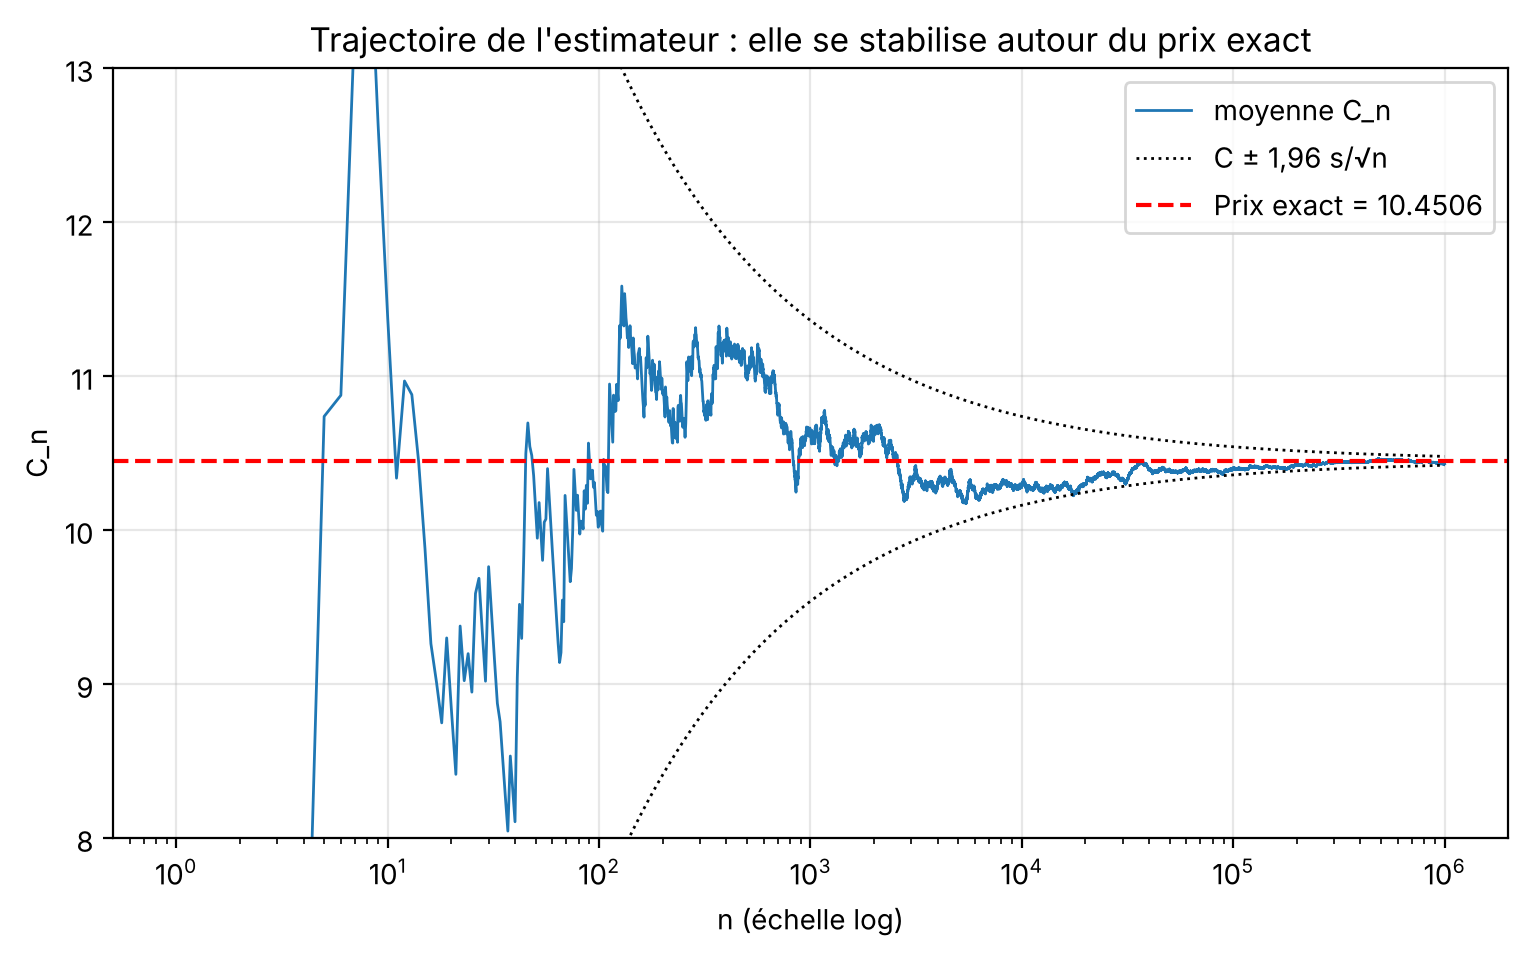

C_n après 1 000 payoffs     : 10.6402
C_n après 1 000 000 payoffs : 10.4308   (C exact = 10.4506)


In [7]:
# ============ Trajectoire de la moyenne C_n ============
Z  = box_muller(N, rng)
ST = S0 * np.exp((r - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * Z)
Y  = np.exp(-r * T) * np.maximum(ST - K, 0.0)
n  = np.arange(1, N + 1)
C_n = np.cumsum(Y) / n                          # moyenne des n premiers payoffs

plt.figure(figsize=(9, 5))
plt.plot(n, C_n, lw=1, label="moyenne C_n")
plt.plot(n, C_exact + z95 * Y.std() / np.sqrt(n), "k:", lw=1, label="C ± 1,96 s/√n")
plt.plot(n, C_exact - z95 * Y.std() / np.sqrt(n), "k:", lw=1)
plt.axhline(C_exact, color="red", ls="--", label=f"Prix exact = {C_exact:.4f}")
plt.xscale("log"); plt.ylim(8, 13); plt.xlabel("n (échelle log)"); plt.ylabel("C_n")
plt.title("Trajectoire de l'estimateur : elle se stabilise autour du prix exact")
plt.legend(); plt.grid(alpha=0.3)
plt.savefig("figures/fig_trajectoire.png", dpi=160, bbox_inches="tight")
plt.show()
print(f"C_n après 1 000 payoffs     : {C_n[999]:.4f}")
print(f"C_n après 1 000 000 payoffs : {C_n[-1]:.4f}   (C exact = {C_exact:.4f})")

## 5. Méthode des variables antithétiques

Pour chaque tirage $Z$, on utilise aussi $-Z$, qui a la même loi. On fait la moyenne des deux payoffs. Pour garder le **même budget** ($N$ payoffs), on tire $N/2$ valeurs de $Z$. Comme pour le standard, on calcule l'erreur $|C_{\text{analytique}} - \hat C_a|$.

In [8]:
# ============ Variables antithétiques ============
def mc_call_antithetic(N, rng):
    Z = box_muller(N // 2, rng)                                  # N/2 tirages
    ST_plus  = S0 * np.exp((r - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * Z)    # prix final avec Z
    ST_minus = S0 * np.exp((r - 0.5 * sigma**2) * T - sigma * np.sqrt(T) * Z)    # prix final avec -Z
    Y_plus   = np.exp(-r * T) * np.maximum(ST_plus - K, 0.0)                     # payoff avec Z
    Y_minus  = np.exp(-r * T) * np.maximum(ST_minus - K, 0.0)                    # payoff avec -Z
    Y_anti   = (Y_plus + Y_minus) / 2                                            # moyenne de chaque paire
    prix = Y_anti.mean()
    se   = Y_anti.std(ddof=1) / np.sqrt(N // 2)
    return prix, se

C_a, se_a = mc_call_antithetic(N, rng)
print(f"C_a = {C_a:.4f}   SE = {se_a:.5f}   (standard : SE = {se_mc:.5f})")
print(f"Erreur |C_analytique - C_a| = {abs(C_exact - C_a):.6f}")

C_a = 10.4600   SE = 0.01039   (standard : SE = 0.01471)
Erreur |C_analytique - C_a| = 0.009445


## 6. Méthode de la variable de contrôle et calcul de $c$

On utilise $X = S_T$, dont l'espérance est connue exactement : $\mathbb E[S_T] = S_0e^{rT}$. Le nouvel estimateur est
$$Y_c = Y - c\,(X - \mathbb E[X]),\qquad c^* = \frac{\operatorname{Cov}(Y, X)}{\operatorname{Var}(X)}.$$
**$c$ analytique.** Avec la loi log-normale de $S_T$, on calcule $c^*$ exactement :
$\mathbb E[S_T\mathbf 1_{S_T>K}] = S_0e^{rT}N(d_1)$, $\ \mathbb E[S_T^2\mathbf 1_{S_T>K}] = S_0^2e^{(2r+\sigma^2)T}N(d_1+\sigma\sqrt T)$, $\ \operatorname{Var}(S_T) = S_0^2e^{2rT}(e^{\sigma^2T}-1)$, et
$$\operatorname{Cov}(Y,S_T) = e^{-rT}\big(\mathbb E[S_T^2\mathbf 1_{S_T>K}] - K\,\mathbb E[S_T\mathbf 1_{S_T>K}]\big) - C\,\mathbb E[S_T].$$
On compare ce $c$ analytique au $c^*$ de la simulation : erreur $= |c_{\text{analytique}} - c^*|$, et le prix au prix analytique : erreur $= |C_{\text{analytique}} - \hat C_c|$.

In [9]:
# ============ Variable de contrôle ============
def mc_call_control(N, rng):
    Z  = box_muller(N, rng)
    ST = S0 * np.exp((r - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * Z)
    Y  = np.exp(-r * T) * np.maximum(ST - K, 0.0)

    X  = ST                          # variable de contrôle
    EX = S0 * np.exp(r * T)          # son espérance exacte

    c_star = np.cov(Y, X)[0, 1] / np.var(X, ddof=1)    # c* = Cov(Y,X) / Var(X)

    Y_c  = Y - c_star * (X - EX)     # estimateur corrigé
    prix = Y_c.mean()
    se   = Y_c.std(ddof=1) / np.sqrt(N)
    return prix, se, c_star

C_c, se_c, c_star = mc_call_control(N, rng)
print(f"C_c = {C_c:.4f}   SE = {se_c:.5f}   (standard : SE = {se_mc:.5f})")
print(f"Erreur |C_analytique - C_c| = {abs(C_exact - C_c):.6f}")

# ============ c analytique (formule exacte) et erreur ============
d1 = (np.log(S0 / K) + (r + sigma**2 / 2) * T) / (sigma * np.sqrt(T))
E_ST    = S0 * np.exp(r * T)                                                          # E[S_T]
E_ST_1  = E_ST * norm.cdf(d1)                                                         # E[S_T 1{S_T > K}]
E_ST2_1 = S0**2 * np.exp((2 * r + sigma**2) * T) * norm.cdf(d1 + sigma * np.sqrt(T))  # E[S_T² 1{S_T > K}]
cov_exact = np.exp(-r * T) * (E_ST2_1 - K * E_ST_1) - C_exact * E_ST                  # Cov(Y, S_T)
var_exact = S0**2 * np.exp(2 * r * T) * (np.exp(sigma**2 * T) - 1)                    # Var(S_T)
c_analytique = cov_exact / var_exact

print(f"\nc analytique   = {c_analytique:.6f}")
print(f"c* simulation  = {c_star:.6f}")
print(f"Erreur |c_analytique - c*| = {abs(c_analytique - c_star):.6f}")

C_c = 10.4472   SE = 0.00562   (standard : SE = 0.01471)
Erreur |C_analytique - C_c| = 0.003408

c analytique   = 0.640762
c* simulation  = 0.640505
Erreur |c_analytique - c*| = 0.000257


## 7. Justification théorique

**Variables antithétiques.** $Z$ et $-Z$ ont la même loi, donc $\mathbb E[Y^-] = \mathbb E[Y^+] = C$ : pas de biais. Le payoff est croissant en $Z$, donc $Y^+$ et $Y^-$ varient en sens inverse : $\operatorname{Cov}(Y^+, Y^-) < 0$ et
$$\operatorname{Var}\Big(\frac{Y^+ + Y^-}{2}\Big) = \frac{\operatorname{Var}(Y)}{2}\,(1 + \rho),\qquad \rho = \operatorname{Corr}(Y^+, Y^-) < 0 .$$

**Variable de contrôle.** Pour tout $c$, $\mathbb E[Y_c] = C$ (pas de biais). La variance
$$g(c) = \operatorname{Var}(Y) - 2c\operatorname{Cov}(Y,X) + c^2\operatorname{Var}(X)$$
est une parabole en $c$. On dérive : $g'(c) = -2\operatorname{Cov}(Y,X) + 2c\operatorname{Var}(X) = 0$, donc
$$c^* = \frac{\operatorname{Cov}(Y,X)}{\operatorname{Var}(X)},\qquad \operatorname{Var}(Y_{c^*}) = \operatorname{Var}(Y)\,(1 - \rho_{XY}^2).$$

## 8. Comparaison des trois estimateurs

On reprend les trois résultats calculés plus haut, à budget égal ($N$ payoffs chacun), et on compare :
- l'erreur standard $SE$ et l'intervalle de confiance à 95 % ;
- l'erreur quadratique moyenne : les trois estimateurs sont sans biais, donc $MSE = \mathbb E[(\hat C - C)^2] = \operatorname{Var}(\hat C) = SE^2$ ;
- le **gain de variance** $= SE_{\text{standard}}^2 / SE^2$ : combien de fois moins de simulations il faut pour la même précision ;
- le temps de calcul et l'**efficacité** $=$ gain $\times\ t_{\text{standard}} / t$ : le gain réel, temps compris.

In [10]:
# ============ Comparaison des trois estimateurs ============
methodes  = {"Standard": mc_call_standard, "Antithétique": mc_call_antithetic, "Contrôle": mc_call_control}
resultats = {"Standard": (C_mc, se_mc), "Antithétique": (C_a, se_a), "Contrôle": (C_c, se_c)}

# temps de calcul : moyenne sur 5 exécutions, avec un générateur à part (rng n'est pas modifié)
rng_t = np.random.default_rng(0)
temps = {}
for nom, methode in methodes.items():
    t0 = time.perf_counter()
    for _ in range(5):
        methode(N, rng_t)
    temps[nom] = (time.perf_counter() - t0) / 5

print(f"Prix exact C = {C_exact:.4f}\n")
print(f"{'Méthode':<13}| {'Prix':>8} | {'SE':>8} | {'IC 95 %':^19} | {'MSE = SE²':>9} | {'Gain var':>8} | {'Temps (s)':>9} | {'Efficacité':>10}")
print("-" * 106)
for nom, (prix, se) in resultats.items():
    gain = (se_mc / se)**2
    t = temps[nom]
    print(f"{nom:<13}| {prix:8.4f} | {se:8.5f} | [{prix - z95*se:.4f} ; {prix + z95*se:.4f}] | {se**2:9.6f} | "
          f"x{gain:7.2f} | {t:9.4f} | x{gain * temps['Standard'] / t:9.2f}")

Prix exact C = 10.4506

Méthode      |     Prix |       SE |       IC 95 %       | MSE = SE² | Gain var | Temps (s) | Efficacité
----------------------------------------------------------------------------------------------------------
Standard     |  10.4370 |  0.01471 | [10.4081 ; 10.4658] |  0.000216 | x   1.00 |    0.0385 | x     1.00
Antithétique |  10.4600 |  0.01039 | [10.4397 ; 10.4804] |  0.000108 | x   2.00 |    0.0222 | x     3.48
Contrôle     |  10.4472 |  0.00562 | [10.4362 ; 10.4582] |  0.000032 | x   6.86 |    0.0559 | x     4.72


Le **meilleur estimateur** est celui qui a la plus petite erreur standard (donc l'IC le plus étroit), à temps de calcul comparable : ici la **variable de contrôle**. On ne choisit pas sur l'écart $|\hat C - C|$ d'une seule simulation, qui dépend du hasard.

### Courbe de comparaison des trois méthodes

Pour chaque méthode, on suit l'estimation au fur et à mesure que le nombre de payoffs augmente (même budget). Les trois courbes convergent vers le prix exact ; la méthode la plus précise est celle dont la courbe oscille le moins (ici la variable de contrôle, en vert).

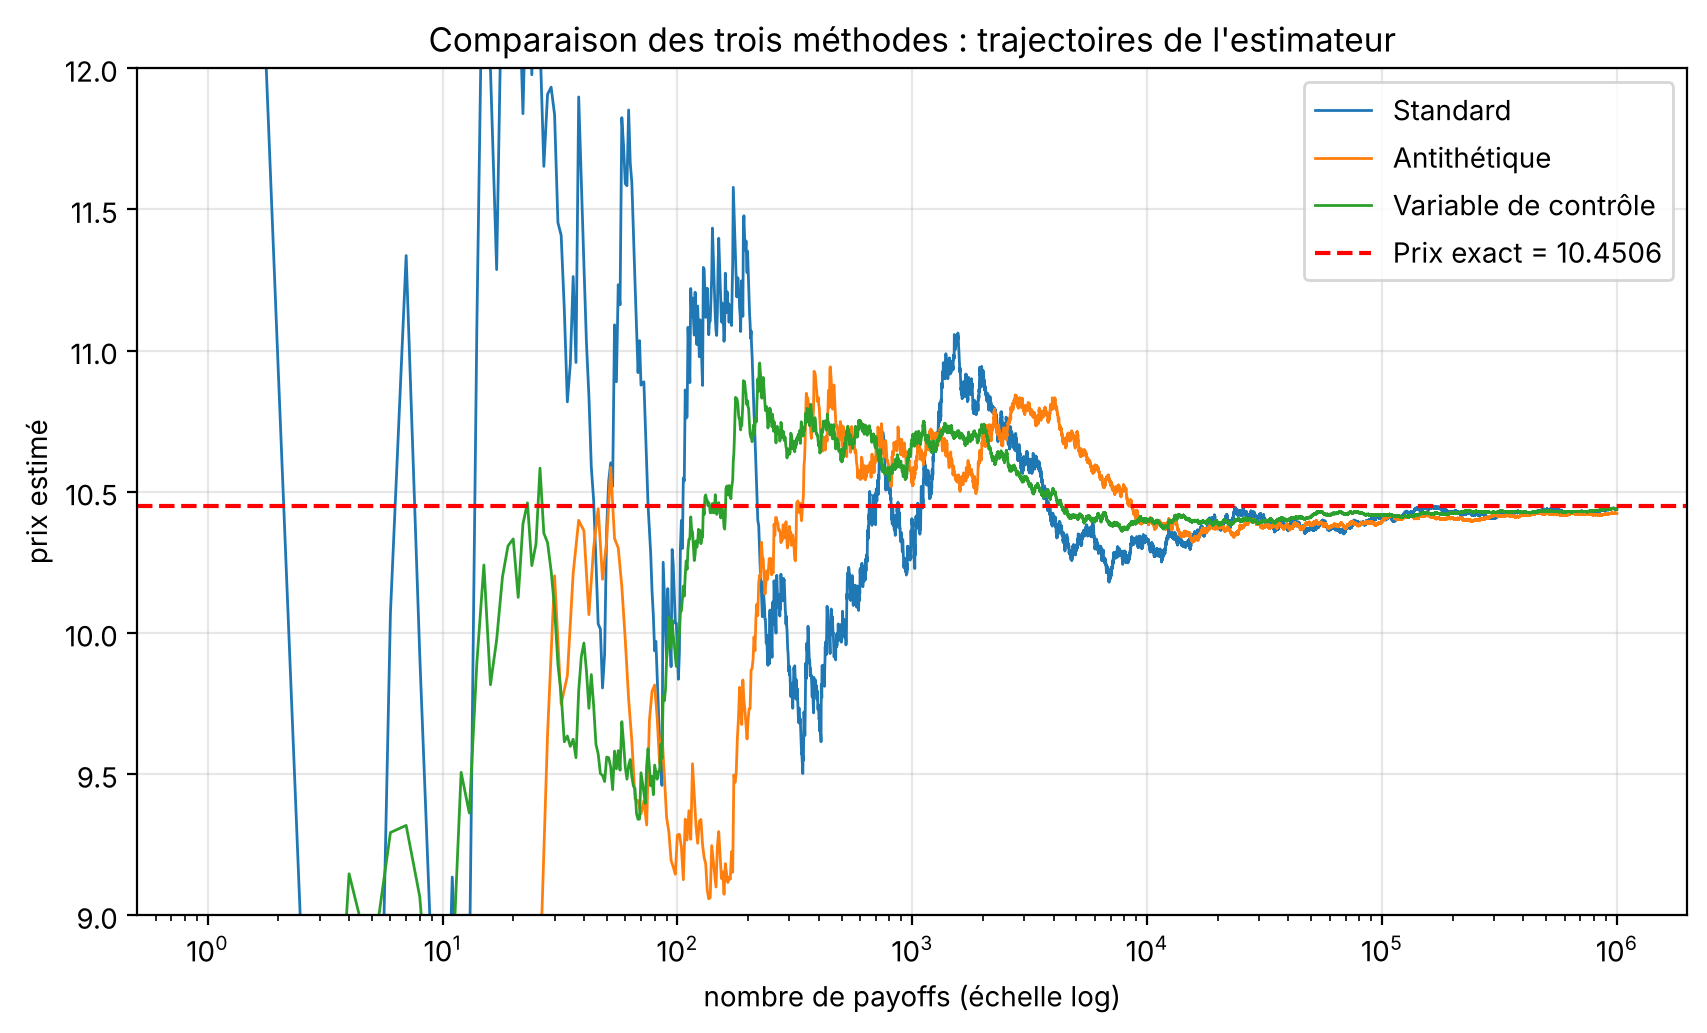

In [11]:
# ============ Trajectoires des trois méthodes ============
Z  = box_muller(N, rng)
ST = S0 * np.exp((r - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * Z)
Y  = np.exp(-r * T) * np.maximum(ST - K, 0.0)                        # standard

Za = Z[:N // 2]                                                      # antithétique : N/2 paires = N payoffs
Y_plus  = np.exp(-r * T) * np.maximum(S0 * np.exp((r - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * Za) - K, 0.0)
Y_minus = np.exp(-r * T) * np.maximum(S0 * np.exp((r - 0.5 * sigma**2) * T - sigma * np.sqrt(T) * Za) - K, 0.0)
Y_anti  = (Y_plus + Y_minus) / 2

Y_c = Y - c_star * (ST - S0 * np.exp(r * T))                         # contrôle (c* de la partie 6)

n  = np.arange(1, N + 1)
na = np.arange(1, N // 2 + 1)
plt.figure(figsize=(10, 5.5))
plt.plot(n, np.cumsum(Y) / n, lw=1, label="Standard")
plt.plot(2 * na, np.cumsum(Y_anti) / na, lw=1, label="Antithétique")
plt.plot(n, np.cumsum(Y_c) / n, lw=1, label="Variable de contrôle")
plt.axhline(C_exact, color="red", ls="--", label=f"Prix exact = {C_exact:.4f}")
plt.xscale("log"); plt.ylim(9, 12); plt.xlabel("nombre de payoffs (échelle log)"); plt.ylabel("prix estimé")
plt.title("Comparaison des trois méthodes : trajectoires de l'estimateur")
plt.legend(); plt.grid(alpha=0.3)
plt.savefig("figures/fig_comparaison_3.png", dpi=160, bbox_inches="tight")
plt.show()

### Prix pour les puissances de 10 : les trois méthodes

On refait le calcul de la partie 4 ($N = 10, 100, \dots, 10^6$) avec les trois méthodes, et on compare chaque prix au prix analytique : erreur $= |C_{\text{analytique}} - \hat C|$.

In [12]:
# ============ Puissances de 10 : les trois méthodes ============
print(f"{'N':>9} | {'Standard':>8} {'erreur':>8} | {'Antithét.':>9} {'erreur':>8} | {'Contrôle':>8} {'erreur':>8}")
print("-" * 72)
for n in puissances:
    ligne = f"{n:>9} |"
    for nom, methode in methodes.items():
        p = methode(n, rng)[0]
        ligne += f" {p:8.4f} {abs(C_exact - p):8.4f} |"
    print(ligne[:-2])

        N | Standard   erreur | Antithét.   erreur | Contrôle   erreur
------------------------------------------------------------------------
       10 |   8.3558   2.0948 |   4.7035   5.7471 |  12.4296   1.9790
      100 |   7.6188   2.8318 |  10.2746   0.1760 |  10.9364   0.4858
     1000 |  10.3919   0.0587 |  10.4630   0.0124 |  10.0182   0.4324
    10000 |  10.2897   0.1609 |  10.4057   0.0448 |  10.5298   0.0793
   100000 |  10.4781   0.0275 |  10.4207   0.0299 |  10.4459   0.0046
  1000000 |  10.4486   0.0020 |  10.4693   0.0187 |  10.4516   0.0010


Pour $N$ petit ($10$, $100$), il y a trop peu de tirages : le prix peut être loin de $C$. Quand $N$ grandit, les trois prix se rapprochent de $C$. L'erreur d'une seule simulation dépend du hasard : pour comparer la précision des méthodes, on répète le calcul à $N$ fixé (ci-dessous).

### Stabilité des trois méthodes à $N = 10^6$ fixé

On fixe $N = 10^6$ et on refait le calcul $M = 50$ fois avec chaque méthode (de nouveaux tirages à chaque fois).

Sur la figure, chaque colonne contient les 50 prix d'une méthode. Une méthode **stable** donne des points serrés autour du prix exact (ligne rouge). L'**erreur moyenne** est la moyenne des 50 erreurs $|C_{\text{analytique}} - \hat C|$.

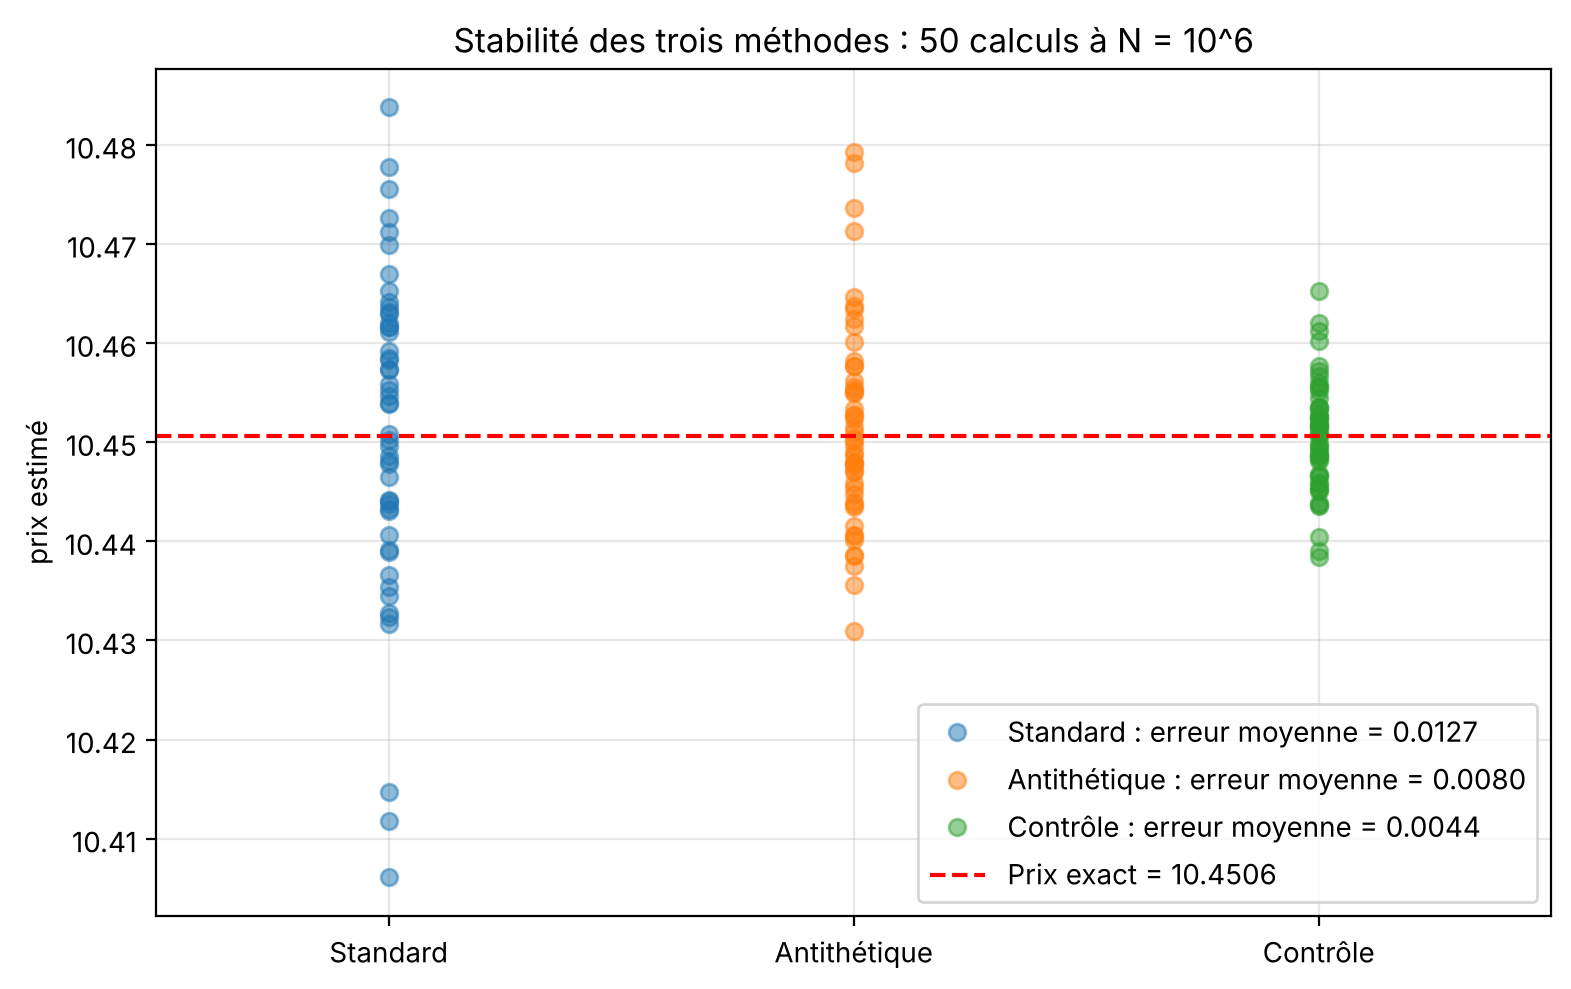

Méthode      |  Moyenne | Écart-type | Erreur moyenne
------------------------------------------------------
Standard     |  10.4512 |    0.01619 |        0.01265
Antithétique |  10.4517 |    0.01052 |        0.00800
Contrôle     |  10.4507 |    0.00567 |        0.00440


In [13]:
# ============ Stabilité à N = 10^6 fixé : 50 répétitions ============
M = 50                                                # nombre de répétitions
estimations = {nom: np.array([methode(N, rng)[0] for _ in range(M)]) for nom, methode in methodes.items()}

plt.figure(figsize=(9, 5.5))
for i, (nom, prix_M) in enumerate(estimations.items()):
    erreur_moy = np.abs(C_exact - prix_M).mean()                     # erreur moyenne des 50 calculs
    plt.plot(np.full(M, i), prix_M, "o", alpha=0.5, label=f"{nom} : erreur moyenne = {erreur_moy:.4f}")
plt.axhline(C_exact, color="red", ls="--", label=f"Prix exact = {C_exact:.4f}")
plt.xticks(range(3), list(estimations)); plt.xlim(-0.5, 2.5)
plt.ylabel("prix estimé"); plt.title("Stabilité des trois méthodes : 50 calculs à N = 10^6")
plt.legend(loc="lower right"); plt.grid(alpha=0.3)
plt.savefig("figures/fig_stabilite_3.png", dpi=160, bbox_inches="tight")
plt.show()

print(f"{'Méthode':<13}| {'Moyenne':>8} | {'Écart-type':>10} | {'Erreur moyenne':>14}")
print("-" * 54)
for nom, prix_M in estimations.items():
    print(f"{nom:<13}| {prix_M.mean():8.4f} | {prix_M.std(ddof=1):10.5f} | {np.abs(C_exact - prix_M).mean():14.5f}")

Les trois colonnes sont centrées sur le prix exact (pas de biais). La colonne de la **variable de contrôle** est la plus serrée : c'est la méthode la plus stable, et son erreur moyenne est environ 3 fois plus petite que celle du standard. L'écart-type des 50 prix est proche de l'erreur standard $SE$ calculée plus haut, ce qui confirme les intervalles de confiance.

## 9. Courbe de gain

On trace l'erreur standard des trois méthodes en fonction de $N$.

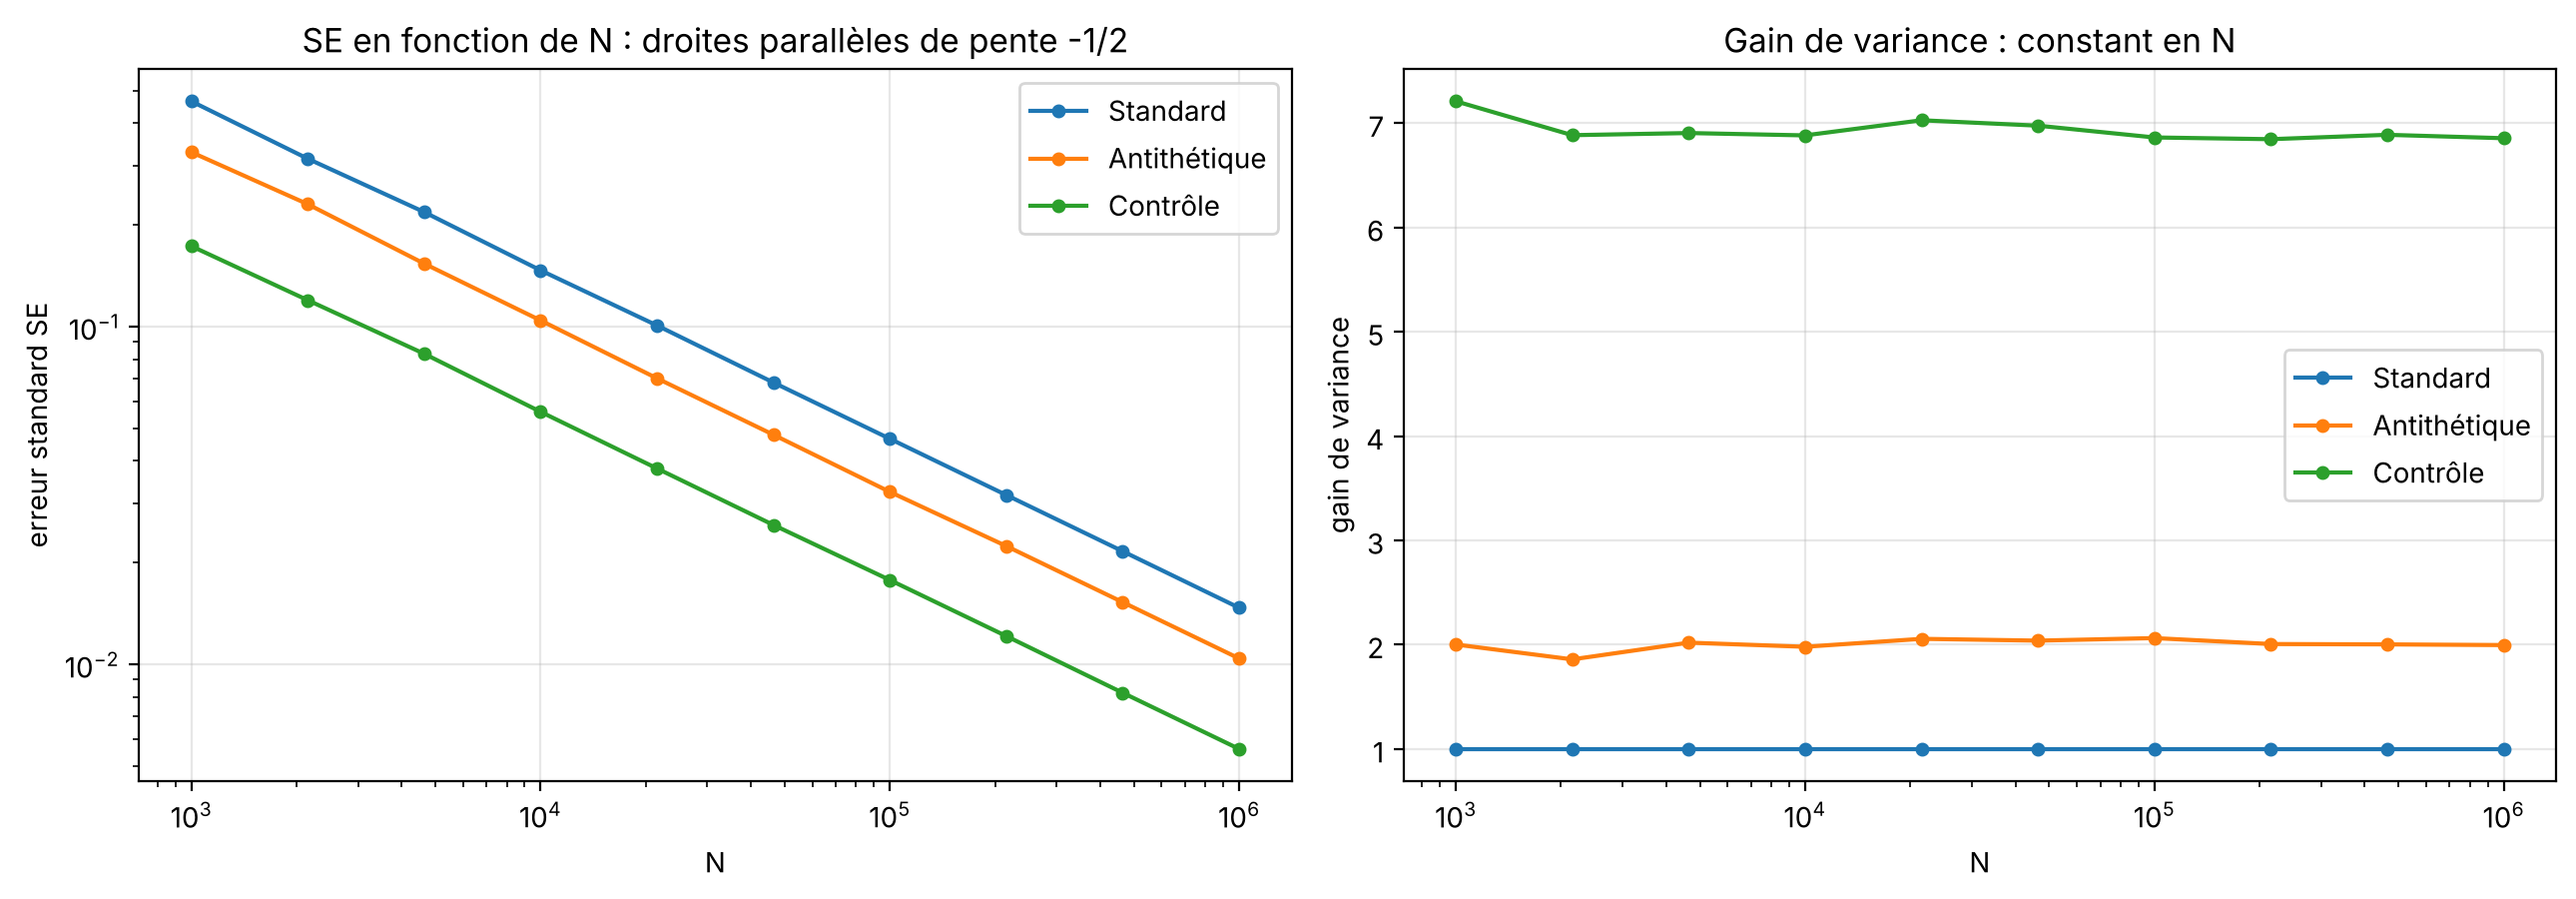

In [14]:
# ============ Courbe de gain ============
liste_N = np.unique(np.logspace(3, 6, 10).astype(int))
se_par_methode = {nom: [] for nom in methodes}
for n in liste_N:
    for nom, methode in methodes.items():
        se_par_methode[nom].append(methode(n, rng)[1])

fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
for nom in methodes:
    ax[0].loglog(liste_N, se_par_methode[nom], "o-", ms=4, label=nom)
    gain = (np.array(se_par_methode["Standard"]) / np.array(se_par_methode[nom]))**2
    ax[1].semilogx(liste_N, gain, "o-", ms=4, label=nom)
ax[0].set_xlabel("N"); ax[0].set_ylabel("erreur standard SE"); ax[0].set_title("SE en fonction de N : droites parallèles de pente -1/2")
ax[1].set_xlabel("N"); ax[1].set_ylabel("gain de variance"); ax[1].set_title("Gain de variance : constant en N")
for a in ax: a.legend(); a.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("figures/fig_courbe_gain.png", dpi=160, bbox_inches="tight")
plt.show()

## Conclusion
- **Box-Muller** fabrique des tirages $\mathcal N(0,1)$ à partir d'uniformes.
- Le **Monte-Carlo standard** retrouve le prix exact ; l'erreur standard décroît en $1/\sqrt N$.
- À budget égal, les **variables antithétiques** divisent la variance par environ 2, la **variable de contrôle** par environ 7 : c'est la méthode la plus efficace.
- Les deux méthodes ne changent pas la vitesse $1/\sqrt N$ : elles abaissent la droite d'erreur.